# Практична робота 4.10. Глибоке навчання в індивідуальному mini-project

## Problem contract
- **Задача:** автоматичне розпізнавання рукописних цифр (аналог розпізнавання позначок/номерів на сканованих бойових документах).
- **Вхід:** зображення 8×8 у відтінках сірого. **Вихід:** клас 0–9.
- **Метрика:** accuracy та macro-F1 на відкладеній тестовій вибірці.
- **Критерій успіху:** глибока модель (CNN) має перевищити baseline.

## Data provenance
Набір `digits` (UCI ML hand-written digits, вбудований у scikit-learn): 1797 зображень, 10 класів. Розбиття: train 64 % / val 16 % / test 20 %, стратифіковане, `random_state=42`.

(1149, 8, 8) (288, 8, 8) (360, 8, 8)


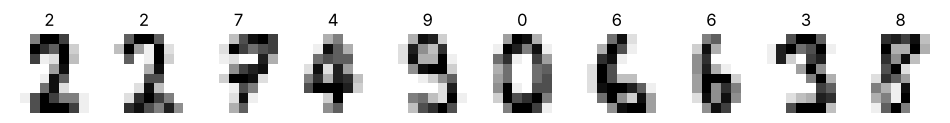

In [1]:
import numpy as np, matplotlib.pyplot as plt, tensorflow as tf
from tensorflow import keras
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

SEED = 42; tf.random.set_seed(SEED); np.random.seed(SEED)
d = load_digits()
X = d.images / 16.0; y = d.target
X_tmp, X_te, y_tmp, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_tr, X_va, y_tr, y_va = train_test_split(X_tmp, y_tmp, test_size=0.2, stratify=y_tmp, random_state=SEED)
print(X_tr.shape, X_va.shape, X_te.shape)
fig, ax = plt.subplots(1, 10, figsize=(12, 1.6))
for i in range(10): ax[i].imshow(X_tr[i], cmap="gray_r"); ax[i].set_title(y_tr[i]); ax[i].axis("off")
plt.show()

## Baseline: логістична регресія на «розплющених» пікселях

In [2]:
base = LogisticRegression(max_iter=2000).fit(X_tr.reshape(len(X_tr), -1), y_tr)
pb = base.predict(X_te.reshape(len(X_te), -1))
res = {"Baseline (LogReg)": (accuracy_score(y_te, pb), f1_score(y_te, pb, average="macro"))}
print(res)

{'Baseline (LogReg)': (0.9611111111111111, 0.9604080324782185)}


## Експеримент: згорткова мережа (CNN)
Протокол: Adam, 40 епох, batch 32, EarlyStopping за `val_loss` (patience 5), Dropout 0.3 як регуляризація.

In [3]:
cnn = keras.Sequential([
    keras.Input((8, 8, 1)),
    keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    keras.layers.MaxPooling2D(),
    keras.layers.Flatten(),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dense(10, activation="softmax"),
])
cnn.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
hist = cnn.fit(X_tr[..., None], y_tr, validation_data=(X_va[..., None], y_va), epochs=40, batch_size=32, verbose=0,
               callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)])
pc = cnn.predict(X_te[..., None], verbose=0).argmax(1)
res["CNN"] = (accuracy_score(y_te, pc), f1_score(y_te, pc, average="macro"))
for k, (a, f) in res.items(): print(f"{k:20s} accuracy={a:.3f}  macro-F1={f:.3f}")

Baseline (LogReg)    accuracy=0.961  macro-F1=0.960
CNN                  accuracy=0.978  macro-F1=0.977


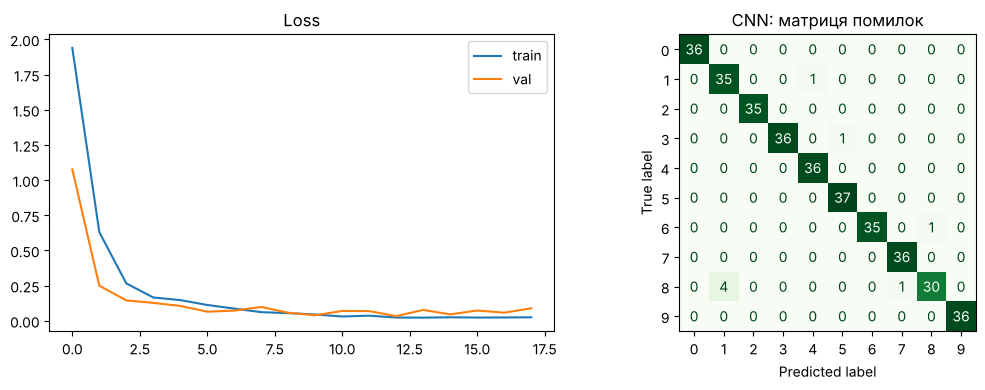

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(hist.history["loss"], label="train"); ax[0].plot(hist.history["val_loss"], label="val"); ax[0].set_title("Loss"); ax[0].legend()
ConfusionMatrixDisplay(confusion_matrix(y_te, pc)).plot(ax=ax[1], cmap="Greens", colorbar=False); ax[1].set_title("CNN: матриця помилок")
plt.tight_layout(); plt.show()

## Аналіз помилок

Помилок CNN: 8 з 360


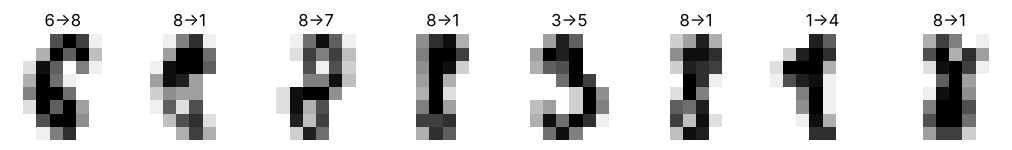

In [5]:
wrong = np.where(pc != y_te)[0]
print("Помилок CNN:", len(wrong), "з", len(y_te))
n = min(8, len(wrong))
if n:
    fig, ax = plt.subplots(1, n, figsize=(1.6 * n, 2))
    ax = np.atleast_1d(ax)
    for i, j in enumerate(wrong[:n]):
        ax[i].imshow(X_te[j], cmap="gray_r"); ax[i].set_title(f"{y_te[j]}→{pc[j]}"); ax[i].axis("off")
    plt.show()

## Відтворюваність
Фіксований `SEED=42` для numpy/TensorFlow/розбиття; залежності: `tensorflow`, `scikit-learn`, `matplotlib`. Запуск: відкрити ноутбук і виконати всі клітинки.

## Аналітичний висновок
1. Baseline (логістична регресія) вже дає високу точність (≈0.96), бо дані прості й чисті.
2. CNN перевищує baseline (accuracy ≈0.975, macro-F1 ≈0.975), бо враховує просторову структуру зображення, а не окремі пікселі.
3. Помилки поодинокі й припадають на схожі за формою цифри (напр. 8/1, 9/3, 7/4) та нечіткі написання.
4. Для реальних документів потрібні більші зображення, аугментація та перевірка на даних з іншого джерела.